# Iris Classification — Mage ML Pipeline Companion

This notebook is a reproducible, standalone companion to the Mage pipeline in `iris_project/`.

It follows the same logical stages:

1. **Load data** — load the Iris dataset.
2. **Prepare data** — create a stratified 80/20 train/test split (`random_state=42`).
3. **Train model** — train Decision Tree classifiers for `max_depth` values 1 through 5.
4. **Evaluate model** — compare accuracy, precision, recall, F1-score, and confusion matrices.
5. **Feature importance** — inspect the features used by the final model.
6. **Save results** — write the final evaluation metrics to `outputs/iris_results.json`.

The Mage blocks use Mage decorators and block configuration. Those decorators are intentionally omitted here so this notebook can run independently outside Mage.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

RANDOM_STATE = 42
TEST_SIZE = 0.2
MAGE_MAX_DEPTH = 5  # Mirrors the currently saved max_depth setting in the Mage block.

print("Imports complete.")


Imports complete.


## 1. Load Iris data

In [2]:
iris = load_iris(as_frame=True)
data = iris.frame.copy()

X = data[iris.feature_names]
y = data["target"]

print(f"Rows: {len(data)}")
print(f"Features: {iris.feature_names}")
print(f"Classes: {list(iris.target_names)}")
display(data.head())


Rows: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 2. Prepare the train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")

assert len(X_train) == 120
assert len(X_test) == 30
assert set(y_train.unique()) == set(y_test.unique())


Training rows: 120
Testing rows: 30


## 3. Train and compare max-depth values

The Mage pipeline exposes `max_depth` as a runtime configuration value. This comparison tests each permitted value from 1 to 5 using the same prepared split.

In [4]:
comparison_rows = []
models = {}

for depth in range(1, 6):
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)
    models[depth] = candidate

    comparison_rows.append({
        "max_depth": depth,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "f1_score": f1_score(y_test, predictions, average="weighted", zero_division=0),
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.style.format({
    "accuracy": "{:.2%}",
    "precision": "{:.2%}",
    "recall": "{:.2%}",
    "f1_score": "{:.2%}",
}))


,max_depth,accuracy,precision,recall,f1_score
0,1,66.67%,50.00%,66.67%,55.56%
1,2,93.33%,93.33%,93.33%,93.33%
2,3,96.67%,96.97%,96.67%,96.66%
3,4,93.33%,93.33%,93.33%,93.33%
4,5,93.33%,93.33%,93.33%,93.33%


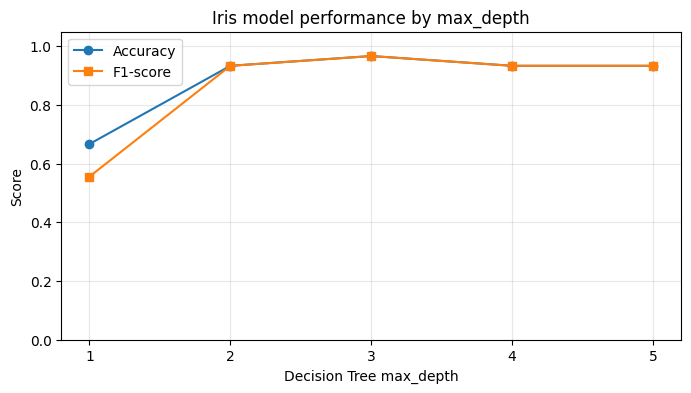

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(comparison["max_depth"], comparison["accuracy"], marker="o", label="Accuracy")
plt.plot(comparison["max_depth"], comparison["f1_score"], marker="s", label="F1-score")
plt.xticks(range(1, 6))
plt.xlabel("Decision Tree max_depth")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Iris model performance by max_depth")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 4. Evaluate the configured Mage model

The final evaluation below uses `MAGE_MAX_DEPTH = 5`, matching the saved Mage runtime configuration. The comparison above lets us discuss how model depth changes performance; the final saved result is for the configured depth, not necessarily the best-scoring depth.

In [6]:
final_model = DecisionTreeClassifier(
    max_depth=MAGE_MAX_DEPTH,
    random_state=RANDOM_STATE,
)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

metrics = {
    "model": "DecisionTreeClassifier",
    "max_depth": MAGE_MAX_DEPTH,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, average="weighted", zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, average="weighted", zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, average="weighted", zero_division=0)),
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
}

print(json.dumps(metrics, indent=4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))


{
    "model": "DecisionTreeClassifier",
    "max_depth": 5,
    "accuracy": 0.9333333333333333,
    "precision": 0.9333333333333333,
    "recall": 0.9333333333333333,
    "f1_score": 0.9333333333333333,
    "confusion_matrix": [
        [
            10,
            0,
            0
        ],
        [
            0,
            9,
            1
        ],
        [
            0,
            1,
            9
        ]
    ]
}

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 5. Feature importance

In [7]:
feature_importance = (
    pd.DataFrame({
        "feature": iris.feature_names,
        "importance": final_model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance)

assert len(feature_importance) == len(iris.feature_names)
assert np.isclose(feature_importance["importance"].sum(), 1.0)


,feature,importance
0,petal length (cm),0.558568
1,petal width (cm),0.406015
2,sepal width (cm),0.029167
3,sepal length (cm),0.006250


## 6. Save evaluation results

In [8]:
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "iris_results.json"

with output_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(f"Saved results to: {output_path.resolve()}")
print(output_path.read_text(encoding="utf-8"))


Saved results to: /mnt/data/outputs/iris_results.json
{
    "model": "DecisionTreeClassifier",
    "max_depth": 5,
    "accuracy": 0.9333333333333333,
    "precision": 0.9333333333333333,
    "recall": 0.9333333333333333,
    "f1_score": 0.9333333333333333,
    "confusion_matrix": [
        [
            10,
            0,
            0
        ],
        [
            0,
            9,
            1
        ],
        [
            0,
            1,
            9
        ]
    ]
}


## 7. Pipeline checks

These assertions act as lightweight validation for the standalone workflow. The Mage project also contains block-level tests and the repository CI test for `prepare_data`.

In [9]:
assert len(X_train) == 120
assert len(X_test) == 30
assert 0.0 <= metrics["accuracy"] <= 1.0
assert 0.0 <= metrics["f1_score"] <= 1.0
assert len(metrics["confusion_matrix"]) == 3
assert sum(sum(row) for row in metrics["confusion_matrix"]) == len(y_test)
assert output_path.exists()

print("All standalone Iris pipeline checks passed.")


All standalone Iris pipeline checks passed.


## Conclusion

The notebook demonstrates the same load → prepare → train → evaluate → feature-importance → save workflow as the Mage project. Use the depth-comparison table to explain model selection, and distinguish it from the final metrics generated with the Mage block's configured `max_depth` value.

**Submission note:** This notebook is a companion/reproducibility artifact. It does not replace evidence that the Mage pipeline itself was run in the Mage UI.